In [ ]:
import pandas as pd
import numpy as np

file_path = '/content/drive/MyDrive/Colab Notebooks/telco_churn_dataset/Telco_customer_churn.xlsx - Telco_Churn.csv'

df = pd.read_csv(file_path)

In [ ]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
# Lowercase, strip extra spaces, and replace spaces with underscores
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

In [ ]:
#listing all the available columns to get a clear view of all the available data
df.columns.tolist()

['customerid',
 'count',
 'country',
 'state',
 'city',
 'zip_code',
 'lat_long',
 'latitude',
 'longitude',
 'gender',
 'senior_citizen',
 'partner',
 'dependents',
 'tenure_months',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method',
 'monthly_charges',
 'total_charges',
 'churn_label',
 'churn_value',
 'churn_score',
 'cltv',
 'churn_reason']

In [ ]:
#removing the invidually identifiable data to anonimize the dataset
df_anon = df.drop(columns=['customerid','count','country','state','city','zip_code','lat_long','latitude','longitude'])

In [ ]:
#displaying the anonimized data
df_anon

,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,online_backup,...,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Female,No,No,No,72,Yes,No,No,No internet service,No internet service,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


In [ ]:
df_anon.churn_value.unique()

array([1, 0])

In [ ]:
df_anon.churn_label.unique()

array(['Yes', 'No'], dtype=object)

In [ ]:
df_anon.churn_reason.unique()

array(['Competitor made better offer', 'Moved',
       'Competitor had better devices',
       'Competitor offered higher download speeds',
       'Competitor offered more data', 'Price too high',
       'Product dissatisfaction', 'Service dissatisfaction',
       'Lack of self-service on Website', 'Network reliability',
       'Limited range of services',
       'Lack of affordable download/upload speed',
       'Long distance charges', 'Extra data charges', "Don't know",
       'Poor expertise of online support',
       'Poor expertise of phone support', 'Attitude of service provider',
       'Attitude of support person', 'Deceased', nan], dtype=object)

In [ ]:
#CLTV stands for customer life time value, they are inversely proportional to the churn rate, higher cltv customer is less likely to churn
#Churn score is a probabilistic value of how likely a customer is to churn
#churn value and the churn label are indicate whether a customer has churned and churn value depicts it in a binary value 1 = yes 0 = no

In [ ]:
#Encoding Categorical variables
# List of your yes/no columns
binary_cols = [
    'dependents', 'partner',
    'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'senior_citizen', 'paperless_billing', 'phone_service', 'multiple_lines',
    'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies'
]

# Replace 'Yes' with 1 and 'No' with 0 across all those columns
df_binary = df_anon.replace({'Yes': 1, 'No': 0, 'No internet service': 0, 'No phone service': 0})

/tmp/ipykernel_607/4110030778.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_binary = df_anon.replace({'Yes': 1, 'No': 0, 'No internet service': 0, 'No phone service': 0})


In [ ]:
df_binary

,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,online_backup,...,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason
0,Male,0,0,0,2,1,0,DSL,1,1,...,Month-to-month,1,Mailed check,53.85,108.15,1,1,86,3239,Competitor made better offer
1,Female,0,0,1,2,1,0,Fiber optic,0,0,...,Month-to-month,1,Electronic check,70.70,151.65,1,1,67,2701,Moved
2,Female,0,0,1,8,1,1,Fiber optic,0,0,...,Month-to-month,1,Electronic check,99.65,820.5,1,1,86,5372,Moved
3,Female,0,1,1,28,1,1,Fiber optic,0,0,...,Month-to-month,1,Electronic check,104.80,3046.05,1,1,84,5003,Moved
4,Male,0,0,1,49,1,1,Fiber optic,0,1,...,Month-to-month,1,Bank transfer (automatic),103.70,5036.3,1,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Female,0,0,0,72,1,0,0,0,0,...,Two year,1,Bank transfer (automatic),21.15,1419.4,0,0,45,5306,NaN
7039,Male,0,1,1,24,1,1,DSL,1,0,...,One year,1,Mailed check,84.80,1990.5,0,0,59,2140,NaN
7040,Female,0,1,1,72,1,1,Fiber optic,0,1,...,One year,1,Credit card (automatic),103.20,7362.9,0,0,71,5560,NaN
7041,Female,0,1,1,11,0,0,DSL,1,0,...,Month-to-month,1,Electronic check,29.60,346.45,0,0,59,2793,NaN


Questions

1.what is the realtionship between the churn value and the number of subscribed services

2.what is the realtionship between the tenure months and churn score

3. does partner and dependants columns affect churn value or churn score

4. does the contract column has any effect on the churn value

5 does senior citizen column affect churn value and churn rate

In [ ]:
subscribed_services = ['online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'phone_service', 'multiple_lines',]



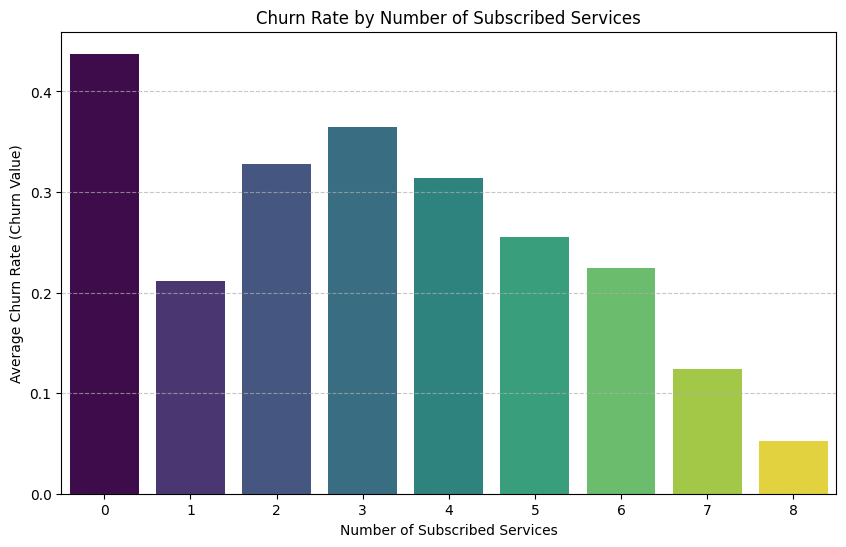

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the total number of subscribed services per customer
df_binary['num_subscribed_services'] = df_binary[subscribed_services].sum(axis=1)

# Calculate mean churn rate for each count of subscribed services
churn_by_services = df_binary.groupby('num_subscribed_services')['churn_value'].mean().reset_index()

# Plot the relationship
plt.figure(figsize=(10, 6))
sns.barplot(x='num_subscribed_services', y='churn_value', data=churn_by_services, palette='viridis', hue='num_subscribed_services', legend=False)
plt.title('Churn Rate by Number of Subscribed Services')
plt.xlabel('Number of Subscribed Services')
plt.ylabel('Average Churn Rate (Churn Value)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

above graph indicates the churn rate by the number of subscribed servies and it is evident that customers with 0 subscribed services has the highest churn rate

In [ ]:
# assigning dummy headers for the subscribed services features to prepare it for the model training
# 1. Sum your binary service columns to create the total_services feature

df_binary['total_services'] = df_binary[subscribed_services].sum(axis=1)

# 2. Convert it to a string/category so pandas knows these are distinct groups, not math numbers
df_binary['total_services'] = df_binary['total_services'].astype(str)

# 3. One-hot encode it (creates individual columns for 0, 1, 2, 3, etc.)
df_binary_services = pd.get_dummies(df_binary, columns=['total_services'], drop_first=True)

In [ ]:
df_binary_services.columns

Index(['gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months',
       'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'monthly_charges', 'total_charges', 'churn_label',
       'churn_value', 'churn_score', 'cltv', 'churn_reason',
       'num_subscribed_services', 'total_services_1', 'total_services_2',
       'total_services_3', 'total_services_4', 'total_services_5',
       'total_services_6', 'total_services_7', 'total_services_8'],
      dtype='object')

In [ ]:
df_binary_services = df_binary_services.drop(columns=subscribed_services)

In [ ]:
df_binary_services.columns

Index(['gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months',
       'internet_service', 'contract', 'paperless_billing', 'payment_method',
       'monthly_charges', 'total_charges', 'churn_label', 'churn_value',
       'churn_score', 'cltv', 'churn_reason', 'num_subscribed_services',
       'total_services_1', 'total_services_2', 'total_services_3',
       'total_services_4', 'total_services_5', 'total_services_6',
       'total_services_7', 'total_services_8'],
      dtype='object')

churn score and tenure months relationship

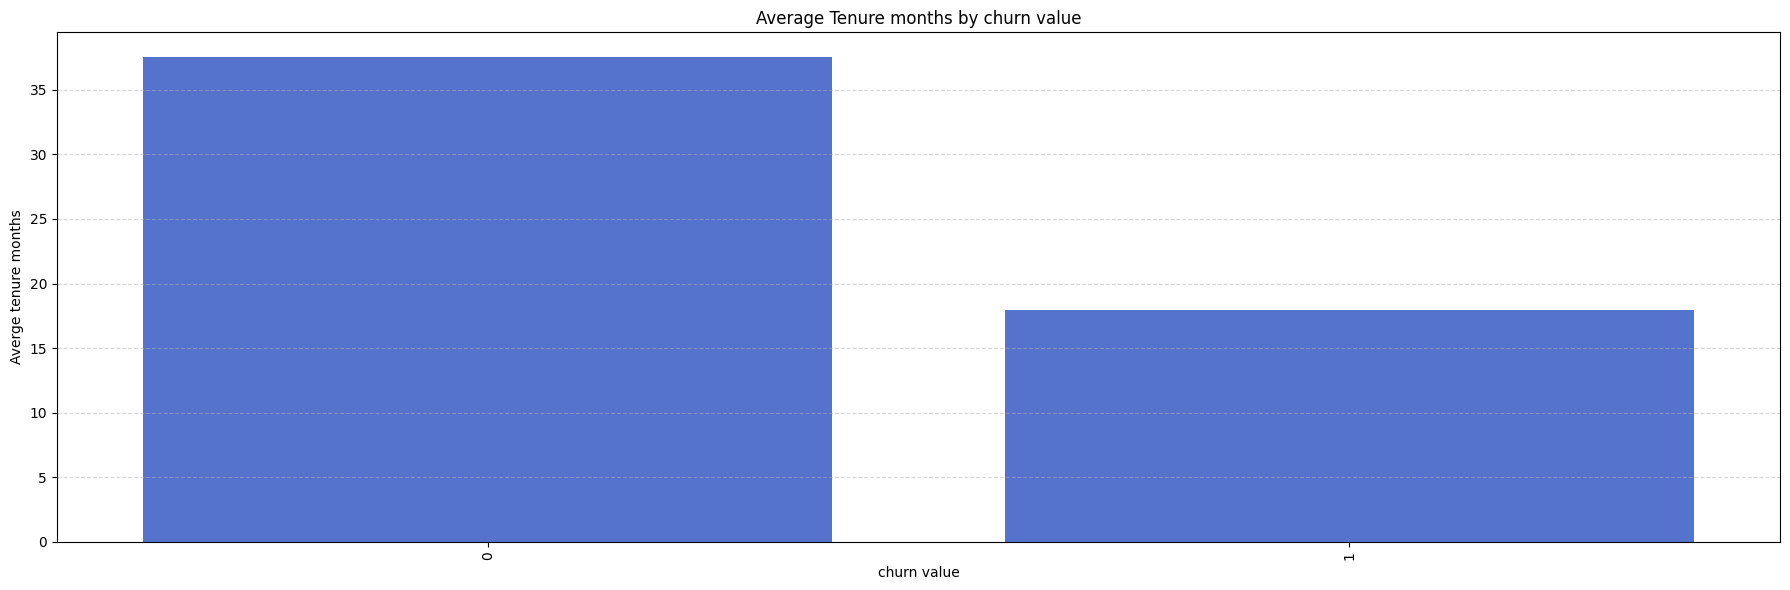

In [ ]:
#realtionship between tenure months and average churn score
import matplotlib.pyplot as plt
import seaborn as sns

# Group by tenure_months and calculate the mean churn score
tenure_churn_score = df_binary.groupby('churn_value')['tenure_months'].mean().reset_index()

# Plot the bar graph
plt.figure(figsize=(18, 6))
sns.barplot(x='churn_value', y='tenure_months', data=tenure_churn_score, color='royalblue')
plt.title('Average Tenure months by churn value')
plt.xlabel('churn value')
plt.ylabel('Averge tenure months')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

it is evident that the higher the tenure months the lower the churn rate is from this graph and it shows that customers who are loyal to the company for a long are bound to stay with the same company for a longer time without churning.

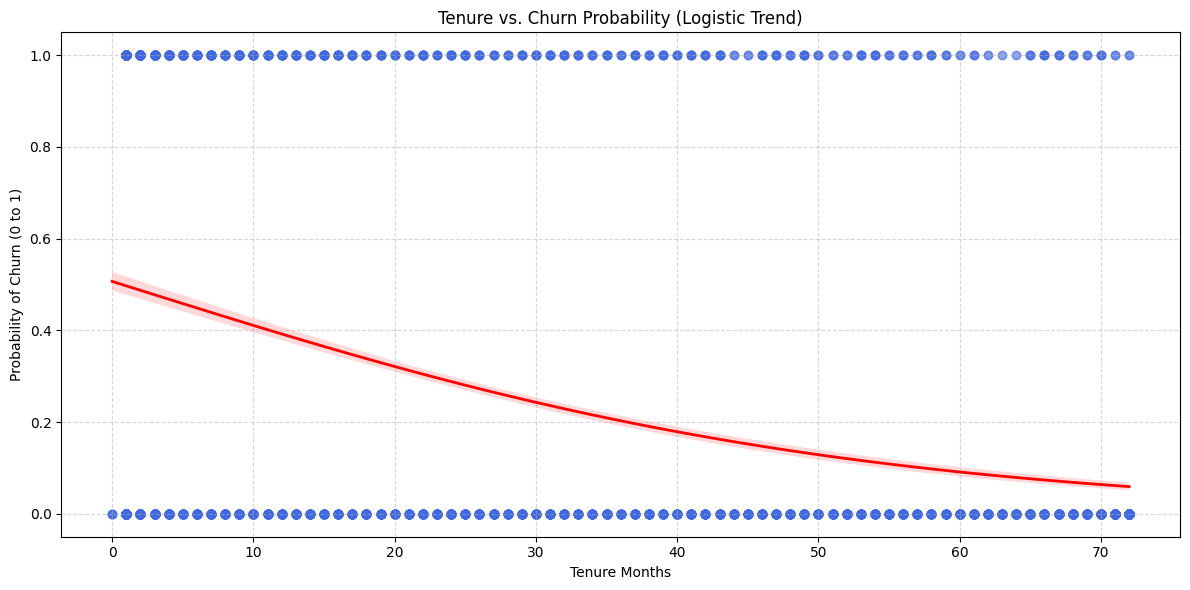

In [ ]:
# a more cleaner graph  of realtionship between tenure months and the churn probability
plt.figure(figsize=(12, 6))

# logistic=True fits an S-curve showing the exact probability of churn
sns.regplot(
    x='tenure_months',
    y='churn_value',
    data=df_binary,
    logistic=True,
    scatter_kws={'alpha': 0.2, 'color': 'royalblue'},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Tenure vs. Churn Probability (Logistic Trend)')
plt.xlabel('Tenure Months')
plt.ylabel('Probability of Churn (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

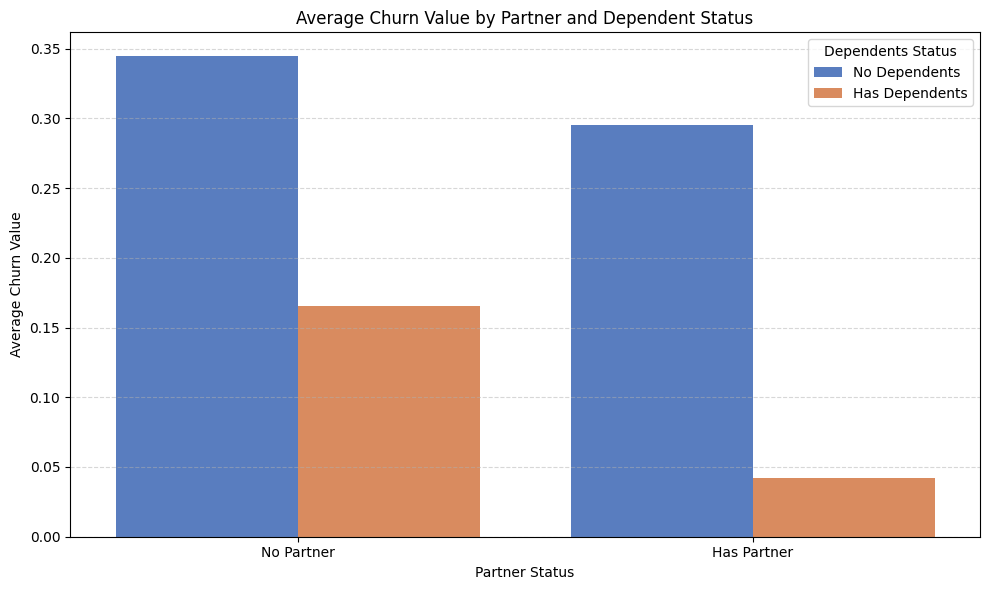

In [ ]:
# Calculate the average churn rate grouped by partner and dependents
partner_dep_churn = df_binary.groupby(['partner', 'dependents'])['churn_value'].mean().reset_index()

# Map 0/1 back to 'No'/'Yes' labels for cleaner visualization
partner_map = {0: 'No Partner', 1: 'Has Partner'}
dep_map = {0: 'No Dependents', 1: 'Has Dependents'}

partner_dep_churn['partner_label'] = partner_dep_churn['partner'].map(partner_map)
partner_dep_churn['dependents_label'] = partner_dep_churn['dependents'].map(dep_map)

# Plot the bar graph
plt.figure(figsize=(10, 6))
sns.barplot(
    x='partner_label',
    y='churn_value',
    hue='dependents_label',
    data=partner_dep_churn,
    palette='muted'
)

plt.title('Average Churn Value by Partner and Dependent Status')
plt.xlabel('Partner Status')
plt.ylabel('Average Churn Value')
plt.legend(title='Dependents Status')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

the above graph shows that customers with dependents are less likely to churn

does the contract column has any effect on the churn value

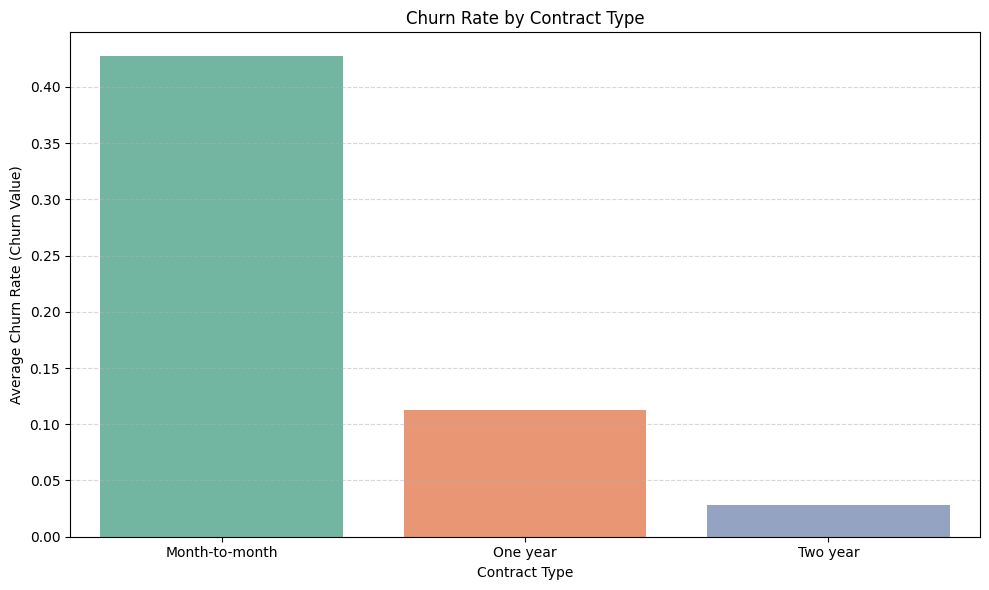

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average churn rate for each contract type
contract_churn = df_binary.groupby('contract')['churn_value'].mean().reset_index()

# Plot the bar graph
plt.figure(figsize=(10, 6))
sns.barplot(
    x='contract',
    y='churn_value',
    data=contract_churn,
    palette='Set2',
    hue='contract',
    legend=False
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Average Churn Rate (Churn Value)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

the above bar graph indicate how the churn rate is lower for customers with longer contracts and churn rate is higher for customers with month-to-month contracts

Effect of seniour citizen column on the churn rate

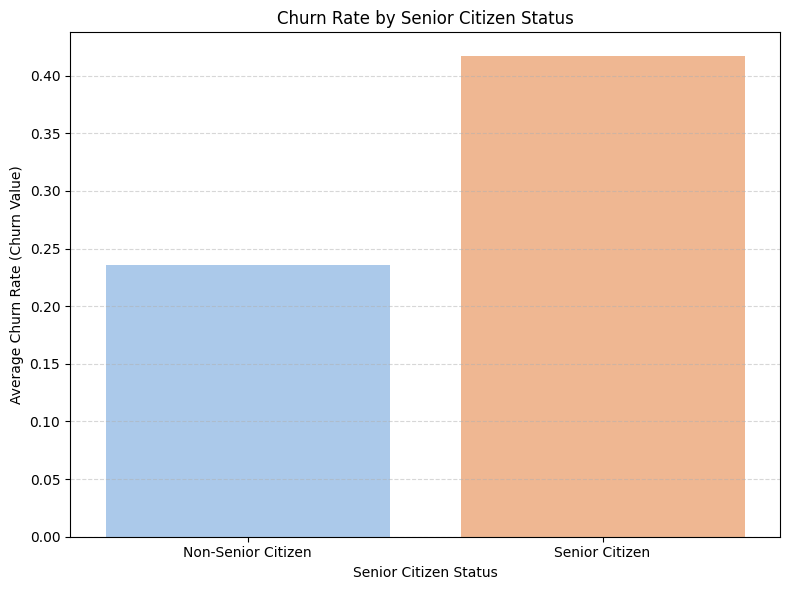

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average churn rate for senior citizens vs non-senior citizens
senior_churn = df_binary.groupby('senior_citizen')['churn_value'].mean().reset_index()

# Map 0 and 1 to descriptive labels
senior_churn['senior_citizen_label'] = senior_churn['senior_citizen'].map({0: 'Non-Senior Citizen', 1: 'Senior Citizen'})

# Plot the bar graph
plt.figure(figsize=(8, 6))
sns.barplot(
    x='senior_citizen_label',
    y='churn_value',
    data=senior_churn,
    palette='pastel',
    hue='senior_citizen_label',
    legend=False
)

plt.title('Churn Rate by Senior Citizen Status')
plt.xlabel('Senior Citizen Status')
plt.ylabel('Average Churn Rate (Churn Value)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

above graph indicates that the senior citizens are most likely to churn.

In [ ]:
# Drop the churn label due to being dulicate of churn score
df_binary = df_binary.drop(columns=['churn_label'])

Training the logistic regression model

In [ ]:
df_binary_services

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

# 1. Define features (X) and target (y) using the requested columns from df_binary
selected_features = subscribed_services + ['senior_citizen', 'tenure_months']
X_selected = df_binary[selected_features]
y_selected = df_binary['churn_value']

# 2. Split the dataset (80% train, 20% test)
X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected, y_selected, test_size=0.2, random_state=42, stratify=y_selected
)

# 3. Initialize and train the Logistic Regression model
log_reg_selected = LogisticRegression(max_iter=1000, random_state=42)
log_reg_selected.fit(X_train_sel, y_train_sel)

# 4. Make predictions and evaluate
y_pred_sel = log_reg_selected.predict(X_test_sel)

print("Model Accuracy (Selected Features):", accuracy_score(y_test_sel, y_pred_sel))
print("\nClassification Report:")
print(classification_report(y_test_sel, y_pred_sel))

# 5. Display coefficients
coeffs_selected = pd.DataFrame({
    'Feature': X_selected.columns,
    'Coefficient': log_reg_selected.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("\nModel Coefficients:")
display(coeffs_selected)

Model Accuracy (Selected Features): 0.7735982966643009

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.92      0.86      1035
           1       0.63      0.36      0.46       374

    accuracy                           0.77      1409
   macro avg       0.71      0.64      0.66      1409
weighted avg       0.75      0.77      0.75      1409


Model Coefficients:


,Feature,Coefficient
7,multiple_lines,0.746822
8,senior_citizen,0.679662
4,streaming_tv,0.666977
5,streaming_movies,0.638825
1,online_backup,0.134983
2,device_protection,0.092850
9,tenure_months,-0.051522
6,phone_service,-0.186077
0,online_security,-0.465437
3,tech_support,-0.548461


In [ ]:
# 1. Generate predictions for the entire test set using our selected features model
y_pred_all = log_reg_selected.predict(X_test_sel)

# 2. Compare predictions with actual labels
correct_predictions = (y_pred_all == y_test_sel)

# 3. Calculate accuracy manually
manual_accuracy = correct_predictions.sum() / len(y_test_sel)

print(f"Total Test Samples: {len(y_test_sel)}")
print(f"Correctly Predicted: {correct_predictions.sum()}")
print(f"Manually Calculated Accuracy: {manual_accuracy:.4f}")

Total Test Samples: 1409
Correctly Predicted: 1090
Manually Calculated Accuracy: 0.7736


In [ ]:
# 1. Get the predicted class probabilities for the first test instance
# predict_proba returns [Probability of Retained (0), Probability of Churned (1)]
probabilities = log_reg_selected.predict_proba(X_test_sel[:1])[0]

# 2. Get the final predicted class from our earlier predictions
pred_class = y_pred_sel[0]
class_label = 'Churned' if pred_class == 1 else 'Retained'
confidence = probabilities[pred_class] * 100

# 3. Print the results adapted to our tenure and churn context
print(f"Predicted Class: {class_label} ({pred_class})")
print(f"Model Confidence: {confidence:.2f}%")
print(f"Probability of Retaining: {probabilities[0]*100:.2f}%")
print(f"Probability of Churning: {probabilities[1]*100:.2f}%")

Predicted Class: Retained (0)
Model Confidence: 94.74%
Probability of Retaining: 94.74%
Probability of Churning: 5.26%
